# Setup

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

from pathlib import Path
import logging
import random

import mlflow
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import numpy as np
from dotenv import load_dotenv

from halcyon.Simulators.SimulationResult import SimulationResult
from halcyon.results.manipulate_results_df import (create_tidy_df_from_mlflow_runs, 
                                                   split_df_into_single_and_double_ko)

from halcyon.results import DfColumnNames

seed = 174
# for CPU
torch.manual_seed(seed)              
# for all GPUs
torch.cuda.manual_seed_all(seed)     
np.random.seed(seed) 
random.seed(seed) 

load_dotenv() 

logging.basicConfig(
    level=logging.INFO, 
    format='%(asctime)s - %(levelname)s - %(message)s',
    force=True  # Important in Jupyter to reset config
)

# Load from MLFlow

## Best ML runs

In [2]:
runs_to_download = []
runs_to_download.extend(mlflow.search_runs(filter_string="attributes.status = 'FINISHED' and params.model_class = 'HybridModel'", experiment_ids=['8'], output_format='list'))
runs_to_download.extend(mlflow.search_runs(filter_string="attributes.status = 'FINISHED' and params.model_class = 'MLP'", experiment_ids=['8'], output_format='list'))
print(len(runs_to_download))

6


In [3]:
import os

os.environ['MLFLOW_ENABLE_ARTIFACTS_PROGRESS_BAR'] = 'False'

In [4]:
raw_predictions_df = create_tidy_df_from_mlflow_runs(runs_to_download)
raw_predictions_df.head()

2026-07-15 13:43:50,818 - INFO - Downloading artifacts for run 6bf6b6a1daf7425bbdc89670fcedb669


2026-07-15 13:43:52,822 - INFO - Downloading artifacts for run ce85d278debb4af08cdb18d49f34cc49
2026-07-15 13:43:54,425 - INFO - Downloading artifacts for run 40d95dee94a045048ca79a979ed31846
2026-07-15 13:43:56,012 - INFO - Downloading artifacts for run 08e71e6d90d048a69937cc1abad098d7
2026-07-15 13:43:57,617 - INFO - Downloading artifacts for run cd96369669654b3f940199ef70619b60
2026-07-15 13:43:59,200 - INFO - Downloading artifacts for run 35a446b344a94f39a6ff6bc091e8b279


,gene,time,predicted_expression,ground_truth,condition,run_id,parent_run_id
0,Node_0,0.0,0.558762,0.558762,KO: Node_36. Env: None,6bf6b6a1daf7425bbdc89670fcedb669,70758f132a104c7b9260d309b738594a
1,Node_1,0.0,0.850469,0.850469,KO: Node_36. Env: None,6bf6b6a1daf7425bbdc89670fcedb669,70758f132a104c7b9260d309b738594a
2,Node_2,0.0,0.693312,0.693312,KO: Node_36. Env: None,6bf6b6a1daf7425bbdc89670fcedb669,70758f132a104c7b9260d309b738594a
3,Node_3,0.0,0.638784,0.638784,KO: Node_36. Env: None,6bf6b6a1daf7425bbdc89670fcedb669,70758f132a104c7b9260d309b738594a
4,Node_4,0.0,0.697619,0.697619,KO: Node_36. Env: None,6bf6b6a1daf7425bbdc89670fcedb669,70758f132a104c7b9260d309b738594a


In [5]:
model_name_records = []
for run_id in raw_predictions_df['run_id'].unique():
    run = mlflow.get_run(run_id)
    model_name_records.append({
        'run_id': run_id,
        'model_name': run.data.tags['mlflow.runName'],
        'modelled_genes': run.data.params.get('modelled_gene_labels', None)})
model_name_df = pd.DataFrame(model_name_records)

In [6]:
import string
genes_to_letter_map = {}
for i, genes in enumerate(model_name_df['modelled_genes'].unique()):
    if genes is None:
        continue
    genes_to_letter_map[genes] = string.ascii_uppercase[i]
genes_to_letter_map
model_name_df['model_name_long'] = model_name_df['model_name'] + ' ' + model_name_df['modelled_genes'].map(genes_to_letter_map).fillna('')
model_name_df['model_name_long'].nunique()
model_name_df

,run_id,model_name,modelled_genes,model_name_long
0,6bf6b6a1daf7425bbdc89670fcedb669,HybridModel,"['Node_9', 'Node_0', 'Node_12', 'Node_37', 'No...",HybridModel A
1,ce85d278debb4af08cdb18d49f34cc49,HybridModel,"['Node_2', 'Node_30', 'Node_3', 'Node_14', 'No...",HybridModel B
2,40d95dee94a045048ca79a979ed31846,HybridModel,"['Node_1', 'Node_16', 'Node_40', 'Node_4', 'No...",HybridModel C
3,08e71e6d90d048a69937cc1abad098d7,HybridModel,"['Node_24', 'Node_6', 'Node_28', 'Node_10', 'N...",HybridModel D
4,cd96369669654b3f940199ef70619b60,HybridModel,"['Node_19', 'Node_5', 'Node_15', 'Node_35', 'N...",HybridModel E
5,35a446b344a94f39a6ff6bc091e8b279,MLP,None,MLP


In [7]:
raw_predictions_df = pd.merge(raw_predictions_df, model_name_df, on='run_id')
raw_predictions_df.head()

,gene,time,predicted_expression,ground_truth,condition,run_id,parent_run_id,model_name,modelled_genes,model_name_long
0,Node_0,0.0,0.558762,0.558762,KO: Node_36. Env: None,6bf6b6a1daf7425bbdc89670fcedb669,70758f132a104c7b9260d309b738594a,HybridModel,"['Node_9', 'Node_0', 'Node_12', 'Node_37', 'No...",HybridModel A
1,Node_1,0.0,0.850469,0.850469,KO: Node_36. Env: None,6bf6b6a1daf7425bbdc89670fcedb669,70758f132a104c7b9260d309b738594a,HybridModel,"['Node_9', 'Node_0', 'Node_12', 'Node_37', 'No...",HybridModel A
2,Node_2,0.0,0.693312,0.693312,KO: Node_36. Env: None,6bf6b6a1daf7425bbdc89670fcedb669,70758f132a104c7b9260d309b738594a,HybridModel,"['Node_9', 'Node_0', 'Node_12', 'Node_37', 'No...",HybridModel A
3,Node_3,0.0,0.638784,0.638784,KO: Node_36. Env: None,6bf6b6a1daf7425bbdc89670fcedb669,70758f132a104c7b9260d309b738594a,HybridModel,"['Node_9', 'Node_0', 'Node_12', 'Node_37', 'No...",HybridModel A
4,Node_4,0.0,0.697619,0.697619,KO: Node_36. Env: None,6bf6b6a1daf7425bbdc89670fcedb669,70758f132a104c7b9260d309b738594a,HybridModel,"['Node_9', 'Node_0', 'Node_12', 'Node_37', 'No...",HybridModel A


Add noiseless expression values

In [8]:
records = []

assert raw_predictions_df['parent_run_id'].nunique() == 1

for run_id in raw_predictions_df['parent_run_id'].unique():
    ml_flow_download_path = mlflow.artifacts.download_artifacts(
        run_id=run_id, artifact_path="dataset"
    )
    sim_output = SimulationResult.load_from_pkl(
        Path(ml_flow_download_path) / "simulation_result.pkl"
    )
    sim_output.noiseless_for_testing = True
    # Get submodules from here currently (bit messy)
    submodules = sim_output.network.get_disconnected_modules()
    long_form_simulation = sim_output.to_long_form_df()
    long_form_simulation[DfColumnNames.RUN_ID_COL] = run_id
    records.append(long_form_simulation)
long_form_simulation = pd.concat(records, ignore_index=True)

2026-07-15 13:44:06,750 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-07-15 13:44:06,766 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-07-15 13:44:06,787 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-07-15 13:44:06,800 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-07-15 13:44:06,815 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-07-15 13:44:06,824 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-07-15 13:44:06,838 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-07-15 13:44:06,854 - WARNING - Connection p

In [9]:
raw_predictions_df.head()

,gene,time,predicted_expression,ground_truth,condition,run_id,parent_run_id,model_name,modelled_genes,model_name_long
0,Node_0,0.0,0.558762,0.558762,KO: Node_36. Env: None,6bf6b6a1daf7425bbdc89670fcedb669,70758f132a104c7b9260d309b738594a,HybridModel,"['Node_9', 'Node_0', 'Node_12', 'Node_37', 'No...",HybridModel A
1,Node_1,0.0,0.850469,0.850469,KO: Node_36. Env: None,6bf6b6a1daf7425bbdc89670fcedb669,70758f132a104c7b9260d309b738594a,HybridModel,"['Node_9', 'Node_0', 'Node_12', 'Node_37', 'No...",HybridModel A
2,Node_2,0.0,0.693312,0.693312,KO: Node_36. Env: None,6bf6b6a1daf7425bbdc89670fcedb669,70758f132a104c7b9260d309b738594a,HybridModel,"['Node_9', 'Node_0', 'Node_12', 'Node_37', 'No...",HybridModel A
3,Node_3,0.0,0.638784,0.638784,KO: Node_36. Env: None,6bf6b6a1daf7425bbdc89670fcedb669,70758f132a104c7b9260d309b738594a,HybridModel,"['Node_9', 'Node_0', 'Node_12', 'Node_37', 'No...",HybridModel A
4,Node_4,0.0,0.697619,0.697619,KO: Node_36. Env: None,6bf6b6a1daf7425bbdc89670fcedb669,70758f132a104c7b9260d309b738594a,HybridModel,"['Node_9', 'Node_0', 'Node_12', 'Node_37', 'No...",HybridModel A


In [10]:
long_form_simulation.head()

,gene,time,ground_truth,condition,run_id
0,Node_0,0.0,0.301563,KO: Node_0. Env: None,70758f132a104c7b9260d309b738594a
1,Node_1,0.0,0.474652,KO: Node_0. Env: None,70758f132a104c7b9260d309b738594a
2,Node_2,0.0,0.631015,KO: Node_0. Env: None,70758f132a104c7b9260d309b738594a
3,Node_3,0.0,0.520979,KO: Node_0. Env: None,70758f132a104c7b9260d309b738594a
4,Node_4,0.0,0.629410,KO: Node_0. Env: None,70758f132a104c7b9260d309b738594a


Merging

In [11]:
outcome = pd.merge(
    raw_predictions_df, 
    long_form_simulation, 
    left_on=['parent_run_id', 'gene', 'time', 'condition'], 
    right_on=['run_id', 'gene', 'time', 'condition'], 
    validate='m:1',
    suffixes=['_from_pred_df', '_from_simulation'])


In [12]:
outcome = outcome[['gene', 'time', 'predicted_expression', 
       'condition', 'run_id_from_pred_df', 'model_name', 'modelled_genes',
       'ground_truth_from_simulation', 'model_name_long']]

outcome = outcome.rename(columns={"run_id_from_pred_df": "run_id", "ground_truth_from_simulation": "noiseless_ground_truth"})

outcome

,gene,time,predicted_expression,condition,run_id,model_name,modelled_genes,noiseless_ground_truth,model_name_long
0,Node_0,0.0,0.558762,KO: Node_36. Env: None,6bf6b6a1daf7425bbdc89670fcedb669,HybridModel,"['Node_9', 'Node_0', 'Node_12', 'Node_37', 'No...",0.301563,HybridModel A
1,Node_1,0.0,0.850469,KO: Node_36. Env: None,6bf6b6a1daf7425bbdc89670fcedb669,HybridModel,"['Node_9', 'Node_0', 'Node_12', 'Node_37', 'No...",0.474652,HybridModel A
2,Node_2,0.0,0.693312,KO: Node_36. Env: None,6bf6b6a1daf7425bbdc89670fcedb669,HybridModel,"['Node_9', 'Node_0', 'Node_12', 'Node_37', 'No...",0.631015,HybridModel A
3,Node_3,0.0,0.638784,KO: Node_36. Env: None,6bf6b6a1daf7425bbdc89670fcedb669,HybridModel,"['Node_9', 'Node_0', 'Node_12', 'Node_37', 'No...",0.520979,HybridModel A
4,Node_4,0.0,0.697619,KO: Node_36. Env: None,6bf6b6a1daf7425bbdc89670fcedb669,HybridModel,"['Node_9', 'Node_0', 'Node_12', 'Node_37', 'No...",0.629410,HybridModel A
...,...,...,...,...,...,...,...,...,...
629995,Node_45,1.0,0.571823,KO: Node_27. Env: None,35a446b344a94f39a6ff6bc091e8b279,MLP,None,0.586141,MLP
629996,Node_46,1.0,0.842800,KO: Node_27. Env: None,35a446b344a94f39a6ff6bc091e8b279,MLP,None,0.790488,MLP
629997,Node_47,1.0,0.800861,KO: Node_27. Env: None,35a446b344a94f39a6ff6bc091e8b279,MLP,None,0.809533,MLP
629998,Node_48,1.0,0.233425,KO: Node_27. Env: None,35a446b344a94f39a6ff6bc091e8b279,MLP,None,0.191893,MLP


In [13]:
outcome['model_name_long'].unique()

array(['HybridModel A', 'HybridModel B', 'HybridModel C', 'HybridModel D',
       'HybridModel E', 'MLP '], dtype=object)

In [14]:
single_ko_df, double_ko_df = split_df_into_single_and_double_ko(outcome)

In [15]:
stdev_df = outcome.groupby(['gene', 'condition'])['noiseless_ground_truth'].std().reset_index().rename(
    columns={'noiseless_ground_truth': 'gene_expression_stdev'})
stdev_df.head()

,gene,condition,gene_expression_stdev
0,Node_0,"KO: Node_0, Node_24. Env: None",0.102010
1,Node_0,KO: Node_0. Env: None,0.067290
2,Node_0,KO: Node_1. Env: None,0.018668
3,Node_0,"KO: Node_10, Node_39. Env: None",0.048064
4,Node_0,KO: Node_10. Env: None,0.026381


In [ ]:
sns.displot(data =stdev_df, x='gene_expression_stdev')

In [ ]:
g = sns.relplot(data=double_ko_df, kind='scatter', x='noiseless_ground_truth', y='predicted_expression', col='model_name_long', s=2, alpha=.2, marker='.')

for ax in g.axes.flat:
    ax.plot([0, 1], [0, 1], 'k--', alpha=0.5)

# Plotting for double KO

In [16]:
from copy import deepcopy
def annotate_kos_in_df(paired):
    paired = deepcopy(paired)
    def make_ko_lookup(df):
        unique_combos = df[['condition', 'modelled_genes']].drop_duplicates()
    
        lookup = {}
        for _, row in unique_combos.iterrows():
            cond = row['condition']
            genes = row['modelled_genes']
            key = (cond, genes)

            kos = re.findall(r"Node_\d+", cond)
        
            if all(f"'{ko}'" in genes for ko in kos):
                ko_in_modelled_genes = 'fully'
            elif any(f"'{ko}'" in genes for ko in kos):
                ko_in_modelled_genes = 'partially'
            else:
                ko_in_modelled_genes = 'none'
        
            lookup[key] = ko_in_modelled_genes
    
        return lookup

    lookup = make_ko_lookup(paired)
    paired['ko_in_mm'] = paired.apply(
    lambda row: lookup[(
        row['condition'],
        row['modelled_genes'] if row['modelled_genes'] is not None else None
    )],
    axis=1
)
    paired['gene_in_mm'] = paired.apply(lambda row:
             bool(re.search(rf"'{row['gene']}'", row['modelled_genes'])), axis=1)
    return paired


In [17]:
def ko_in_same_submodule(df, disconnected_modules):
    df = deepcopy(df)
    for condition in df['condition'].unique():
        kos = re.findall(r"Node_\d+", condition)
        module_indices = []
        for ko in kos:
            module_index = [i for i, module in enumerate(disconnected_modules) if ko in module]
            module_indices.extend(module_index)
        if len(set(module_indices)) == 1:
            df.loc[df['condition'] == condition, 'ko_in_same_submodule'] = True
        else:
            df.loc[df['condition'] == condition, 'ko_in_same_submodule'] = False
    return df


In [18]:
from matplotlib.colors import LogNorm, Normalize
from sklearn.metrics import mean_squared_error
import scipy.cluster.hierarchy as sch
from natsort import natsorted
import re

robust_cmap = True
norm_function = Normalize
cmap = "viridis"

groupby_list = [
    'model_name',
    'modelled_genes',
    DfColumnNames.GENE_COL,
    DfColumnNames.CONDITION_COL,
]
mse_df = (
    double_ko_df.groupby(groupby_list, dropna=False)
    .apply(
        lambda g: mean_squared_error(
            g['noiseless_ground_truth'], g['predicted_expression']
        ),
        include_groups=False,
    )
    .reset_index(name=DfColumnNames.MSE_COL)
)

mlp_mse = mse_df[mse_df['model_name'] == 'MLP'][['gene', 'condition', 'MSE']].rename(columns={'MSE': 'mlp_mse'})
hybrid_mse = mse_df[mse_df['model_name'] == 'HybridModel'][['gene', 'condition', 'MSE', 'modelled_genes']].rename(columns={'MSE': 'hybrid_mse'})

paired = hybrid_mse.merge(mlp_mse, on=['gene', 'condition'])
paired = annotate_kos_in_df(paired)

In [19]:
new_df = ko_in_same_submodule(paired, submodules)

In [20]:
new_df['ko_in_same_submodule'].value_counts()

ko_in_same_submodule
False    12500
Name: count, dtype: int64

In [21]:
new_df[['ko_in_mm', 'gene_in_mm', 'ko_in_same_submodule']].drop_duplicates()

,ko_in_mm,gene_in_mm,ko_in_same_submodule
0,none,False,False
1,partially,False,False
50,none,True,False
51,partially,True,False


In [22]:
paired.head()

,gene,condition,hybrid_mse,modelled_genes,mlp_mse,ko_in_mm,gene_in_mm
0,Node_0,"KO: Node_0, Node_24. Env: None",0.027826,"['Node_1', 'Node_16', 'Node_40', 'Node_4', 'No...",0.026690,none,False
1,Node_0,"KO: Node_10, Node_39. Env: None",0.003808,"['Node_1', 'Node_16', 'Node_40', 'Node_4', 'No...",0.002552,partially,False
2,Node_0,"KO: Node_11, Node_15. Env: None",0.006565,"['Node_1', 'Node_16', 'Node_40', 'Node_4', 'No...",0.004704,none,False
3,Node_0,"KO: Node_11, Node_24. Env: None",0.002897,"['Node_1', 'Node_16', 'Node_40', 'Node_4', 'No...",0.001942,none,False
4,Node_0,"KO: Node_11, Node_28. Env: None",0.001632,"['Node_1', 'Node_16', 'Node_40', 'Node_4', 'No...",0.001599,none,False


In [23]:
mse_df.head()

,model_name,modelled_genes,gene,condition,MSE
0,HybridModel,"['Node_1', 'Node_16', 'Node_40', 'Node_4', 'No...",Node_0,"KO: Node_0, Node_24. Env: None",0.027826
1,HybridModel,"['Node_1', 'Node_16', 'Node_40', 'Node_4', 'No...",Node_0,"KO: Node_10, Node_39. Env: None",0.003808
2,HybridModel,"['Node_1', 'Node_16', 'Node_40', 'Node_4', 'No...",Node_0,"KO: Node_11, Node_15. Env: None",0.006565
3,HybridModel,"['Node_1', 'Node_16', 'Node_40', 'Node_4', 'No...",Node_0,"KO: Node_11, Node_24. Env: None",0.002897
4,HybridModel,"['Node_1', 'Node_16', 'Node_40', 'Node_4', 'No...",Node_0,"KO: Node_11, Node_28. Env: None",0.001632


In [24]:
epistasis_df = pd.read_csv('epistasis_levels_disconnected_modules.csv')

In [25]:
paired = pd.merge(paired, epistasis_df[['condition', 'gene', 'single-to-double-ko-divergence']])
paired.head()

,gene,condition,hybrid_mse,modelled_genes,mlp_mse,ko_in_mm,gene_in_mm,single-to-double-ko-divergence
0,Node_0,"KO: Node_0, Node_24. Env: None",0.027826,"['Node_1', 'Node_16', 'Node_40', 'Node_4', 'No...",0.026690,none,False,0.037662
1,Node_0,"KO: Node_10, Node_39. Env: None",0.003808,"['Node_1', 'Node_16', 'Node_40', 'Node_4', 'No...",0.002552,partially,False,0.059647
2,Node_0,"KO: Node_11, Node_15. Env: None",0.006565,"['Node_1', 'Node_16', 'Node_40', 'Node_4', 'No...",0.004704,none,False,0.047016
3,Node_0,"KO: Node_11, Node_24. Env: None",0.002897,"['Node_1', 'Node_16', 'Node_40', 'Node_4', 'No...",0.001942,none,False,0.052653
4,Node_0,"KO: Node_11, Node_28. Env: None",0.001632,"['Node_1', 'Node_16', 'Node_40', 'Node_4', 'No...",0.001599,none,False,0.055256


In [33]:
def get_row_label(row):
    if row['gene_in_mm']:
        return f"gene in MM,\nKO in mm = {row['ko_in_mm']}"
    else:
        return 'gene not in MM'
paired['row_label'] = paired.apply(get_row_label, axis=1)
paired.head()

,gene,condition,hybrid_mse,modelled_genes,mlp_mse,ko_in_mm,gene_in_mm,single-to-double-ko-divergence,row_label
0,Node_0,"KO: Node_0, Node_24. Env: None",0.027826,"['Node_1', 'Node_16', 'Node_40', 'Node_4', 'No...",0.026690,none,False,0.037662,gene not in MM
1,Node_0,"KO: Node_10, Node_39. Env: None",0.003808,"['Node_1', 'Node_16', 'Node_40', 'Node_4', 'No...",0.002552,partially,False,0.059647,gene not in MM
2,Node_0,"KO: Node_11, Node_15. Env: None",0.006565,"['Node_1', 'Node_16', 'Node_40', 'Node_4', 'No...",0.004704,none,False,0.047016,gene not in MM
3,Node_0,"KO: Node_11, Node_24. Env: None",0.002897,"['Node_1', 'Node_16', 'Node_40', 'Node_4', 'No...",0.001942,none,False,0.052653,gene not in MM
4,Node_0,"KO: Node_11, Node_28. Env: None",0.001632,"['Node_1', 'Node_16', 'Node_40', 'Node_4', 'No...",0.001599,none,False,0.055256,gene not in MM


0.0 0.2


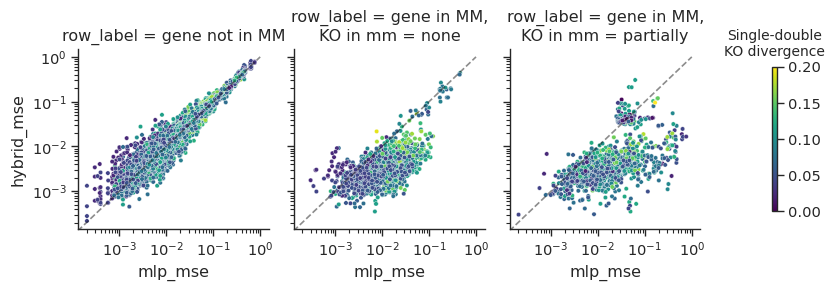

In [51]:
from matplotlib.colors import LogNorm, Normalize
import textwrap 

sns.set_theme()
sns.set_context("paper", font_scale=1.2)
sns.set_style('ticks')


min_scale = round(paired['single-to-double-ko-divergence'].quantile(0.01), 1)
max_scale = round(paired['single-to-double-ko-divergence'].quantile(0.99), 1)

print(min_scale, max_scale)
palette = sns.color_palette()
cmap = 'viridis'
norm = Normalize(min_scale, max_scale)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

g = sns.relplot(data=paired, x='mlp_mse', y='hybrid_mse', col='row_label',
                hue='single-to-double-ko-divergence', 
                alpha=1, s=10 , height=3, aspect=.9, legend=False,
                palette=cmap, hue_norm=norm, 
                )
# g.figure.set_size_inches(9, 3) 
g.set(xscale='log', yscale='log')
for ax in g.axes.flat:
    ax.plot([0, 1], [0, 1], 'k--', alpha=0.5)
    for collection in ax.collections:
        collection.set_rasterized(True)
# for text in g._margin_titles_texts:
#     text.set_visible(False)

cbar = g.figure.colorbar(sm, 
                        ax=g.axes, 
                        shrink=.8,       # scales the bar's length (0 to 1)
                        aspect=30,        # higher = thinner bar (default is ~20)
                        fraction=0.03,    # how much of the figure width it eats up
                        pad=0.1,         # gap between the bar and the last facet
                        )

wrapped_title = textwrap.fill('Single-double KO divergence', width=15)

cbar.ax.set_title(wrapped_title, fontsize=10, pad=8)
cbar.set_ticks(np.arange(min_scale, max_scale+0.05, 0.05))

g.savefig("disconnected_modules_scatterplot_double_ko_three_cols.pdf", dpi=600, bbox_inches='tight')

0.0 0.2


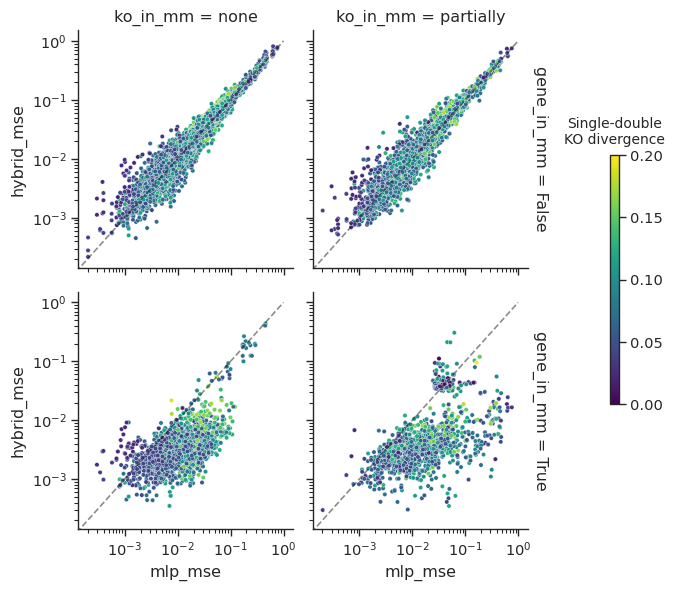

In [48]:
from matplotlib.colors import LogNorm, Normalize
import textwrap 

sns.set_theme()
sns.set_context("paper", font_scale=1.2)
sns.set_style('ticks')

min_scale = round(paired['single-to-double-ko-divergence'].quantile(0.01), 1)
max_scale = round(paired['single-to-double-ko-divergence'].quantile(0.99), 1)


print(min_scale, max_scale)
palette = sns.color_palette()
cmap = 'viridis'
norm = Normalize(min_scale, max_scale)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])


g = sns.relplot(data=paired, x='mlp_mse', y='hybrid_mse', row='gene_in_mm',
                hue='single-to-double-ko-divergence', col='ko_in_mm',
                alpha=1, s=10, facet_kws={'margin_titles': True} , height=3, aspect=1.1,
                palette=cmap, hue_norm=norm, legend=False)
# g.figure.set_size_inches(9, 3) 
g.set(xscale='log', yscale='log')
for ax in g.axes.flat:
    ax.plot([0, 1], [0, 1], 'k--', alpha=0.5)
    for collection in ax.collections:
        collection.set_rasterized(True)
# for text in g._margin_titles_texts:
#     text.set_visible(False)

cbar = g.figure.colorbar(sm, 
                        ax=g.axes, 
                        shrink=0.5,       # scales the bar's length (0 to 1)
                        aspect=30,        # higher = thinner bar (default is ~20)
                        fraction=0.03,    # how much of the figure width it eats up
                        pad=0.15,         # gap between the bar and the last facet
                        )

wrapped_title = textwrap.fill('Single-double KO divergence', width=15)

cbar.ax.set_title(wrapped_title, fontsize=10, pad=8)
cbar.set_ticks(np.arange(min_scale, max_scale+0.05, 0.05))

g.savefig("disconnected_modules_scatterplot_double_ko_hue_divergence.pdf", dpi=600, bbox_inches='tight')

Count how many points hybrid worse than MLP for ko outside mm, but gene in MM

In [35]:
selected_rows = paired[(paired['ko_in_mm'] == 'none') & (paired['gene_in_mm'] == True)]
selected_rows.shape

(1415, 8)

In [36]:
selected_rows.head()

,gene,condition,hybrid_mse,modelled_genes,mlp_mse,ko_in_mm,gene_in_mm,single-to-double-ko-divergence
50,Node_1,"KO: Node_0, Node_24. Env: None",0.266327,"['Node_1', 'Node_16', 'Node_40', 'Node_4', 'No...",0.179252,none,True,0.094793
52,Node_1,"KO: Node_11, Node_15. Env: None",0.001947,"['Node_1', 'Node_16', 'Node_40', 'Node_4', 'No...",0.017776,none,True,0.082657
53,Node_1,"KO: Node_11, Node_24. Env: None",0.001336,"['Node_1', 'Node_16', 'Node_40', 'Node_4', 'No...",0.013560,none,True,0.084893
54,Node_1,"KO: Node_11, Node_28. Env: None",0.004702,"['Node_1', 'Node_16', 'Node_40', 'Node_4', 'No...",0.044076,none,True,0.082221
55,Node_1,"KO: Node_11, Node_29. Env: None",0.001743,"['Node_1', 'Node_16', 'Node_40', 'Node_4', 'No...",0.016309,none,True,0.079057


In [39]:
(selected_rows['hybrid_mse'] > selected_rows['mlp_mse']).value_counts()

False    1267
True      148
Name: count, dtype: int64

In [40]:
148/1415

0.10459363957597173

148 out of 1415 points the hybrid is worse in this case

In [ ]:
sns.set_theme()
sns.set_context("paper", font_scale=1.2)
sns.set_style('ticks')
palette = sns.color_palette()
g = sns.relplot(data=paired, x='mlp_mse', y='hybrid_mse', row='gene_in_mm', hue='gene_in_mm', col='ko_in_mm',
                  alpha=.75, s=10, facet_kws={'margin_titles': True} , height=3, aspect=1,
                palette=palette)
# g.figure.set_size_inches(9, 3) 
g.set(xscale='log', yscale='log')
for ax in g.axes.flat:
    ax.plot([0, 1], [0, 1], 'k--', alpha=0.5)
    for collection in ax.collections:
        collection.set_rasterized(True)
# for text in g._margin_titles_texts:
#     text.set_visible(False)
g.savefig("disconnected_modules_scatterplot_double_ko.pdf", dpi=600, bbox_inches='tight', )

In [ ]:
mse_df

In [ ]:
print(stdev_df)

In [ ]:
paired_with_variation_per_gene = pd.merge(paired, stdev_df, 'left', on=['gene', 'condition', 'nr_genes'])
paired_with_variation_per_gene.shape

In [ ]:
paired_with_variation_per_gene.head()

In [ ]:
sns.set_theme()
sns.set_context("paper", font_scale=1.2)
sns.set_style('ticks')
palette = sns.color_palette()
g = sns.relplot(data=paired_with_variation_per_gene, x='mlp_mse', y='hybrid_mse', col='nr_genes', row='gene_in_mm', hue='gene_in_mm', style='ko_in_mm',
                  alpha=.75, s=10, col_order=natsorted(paired_with_variation_per_gene['nr_genes'].unique()), 
                    facet_kws={'margin_titles': True}, palette=palette)
# g.figure.set_size_inches(9, 3) 
g.set(xscale='log', yscale='log')

# Collect the global min/max across all axes
all_mins, all_maxs = [], []
for ax in g.axes.flat:
    all_mins.append(min(ax.get_xlim()[0], ax.get_ylim()[0]))
    all_maxs.append(max(ax.get_xlim()[1], ax.get_ylim()[1]))

global_min, global_max = min(all_mins), max(all_maxs)

from matplotlib.ticker import LogLocator, LogFormatterMathtext, NullFormatter

ticks = [1e-4, 1e-3, 1e-2, 1e-1, 1e0]
# ticks = [1e-4, 1e-2, 1e0]

for ax in g.axes.flat:
    ax.set_xlim(global_min, global_max)
    ax.set_ylim(global_min, global_max)
    # ax.plot([global_min, global_max], [global_min, global_max], 'k--', lw=0.8, zorder=0)
    ax.set_xticks(ticks)
    ax.set_yticks(ticks)
    ax.xaxis.set_major_formatter(LogFormatterMathtext(labelOnlyBase=True))
    ax.yaxis.set_major_formatter(LogFormatterMathtext(labelOnlyBase=True))
    ax.plot([0, 1], [0, 1], 'k--', alpha=.5, zorder=0)
    for collection in ax.collections:
        collection.set_rasterized(True)


for handle in g.legend.legend_handles:
    try:
        handle.set_markersize(5)
    except AttributeError:
        pass

for text in g._margin_titles_texts:
    text.set_visible(False)

# g.savefig("scatter_mlp_hybrid_log_no_hue.pdf", dpi=600, bbox_inches='tight', )

In [ ]:
sns.set_theme()
sns.set_context("paper", font_scale=1.2)
sns.set_style('ticks')
palette = sns.color_palette()
g = sns.relplot(data=paired_with_variation_per_gene, x='mlp_mse', y='hybrid_mse', col='nr_genes', row='gene_in_mm', hue='gene_expression_stdev', style='ko_in_mm',
                  alpha=.8, s=10, col_order=natsorted(paired_with_variation_per_gene['nr_genes'].unique()), # height=2, aspect=1,
                    facet_kws={'margin_titles': True},  palette='magma',)
# g.figure.set_size_inches(9, 3) 
g.set(xscale='log', yscale='log')

# Collect the global min/max across all axes
all_mins, all_maxs = [], []
for ax in g.axes.flat:
    all_mins.append(min(ax.get_xlim()[0], ax.get_ylim()[0]))
    all_maxs.append(max(ax.get_xlim()[1], ax.get_ylim()[1]))

global_min, global_max = min(all_mins), max(all_maxs)

for ax in g.axes.flat:
    ax.set_xlim(global_min, global_max)
    ax.set_ylim(global_min, global_max)
    ax.plot([0, 1], [0, 1], 'k--', alpha=0.5, zorder=0)
    for collection in ax.collections:
        collection.set_rasterized(True)

for handle in g.legend.legend_handles:
    try:
        handle.set_markersize(5)
    except AttributeError:
        pass

# g.savefig("scatter_mlp_hybrid_log_hue_stdev.pdf", dpi=600, bbox_inches='tight', )

In [ ]:
sns.set_context("paper", font_scale=1.2)
sns.set_style('ticks')
g = sns.relplot(data=paired_with_variation_per_gene, x='mlp_mse', y='hybrid_mse', col='nr_genes', row='gene_in_mm', hue='gene_expression_stdev', style='ko_in_mm',
                  alpha=.75, s=20, col_order=natsorted(paired_with_variation_per_gene['nr_genes'].unique()),  palette='magma',
                    facet_kws={'margin_titles': True})
# g.figure.set_size_inches(9, 3) 
for ax in g.axes.flat:
    ax.plot([0, 1], [0, 1], 'k--', alpha=0.5)
    for collection in ax.collections:
        collection.set_rasterized(True)

for handle in g.legend.legend_handles:
    try:
        handle.set_markersize(5)
    except AttributeError:
        pass

# g.savefig("scatter_mlp_hybrid_lin_hue_stdev.pdf", dpi=600, bbox_inches='tight', )

In [ ]:
selection = paired_with_variation_per_gene[paired_with_variation_per_gene['gene_in_mm'] == True]
g = sns.relplot(data=selection, x='mlp_mse', y='hybrid_mse', col='nr_genes', row='ko_in_mm', hue='gene_expression_stdev', palette='magma',
                  alpha=.8, s=20, height=4, aspect=1, facet_kws={'margin_titles': True}, col_order=natsorted(paired_with_variation_per_gene['nr_genes'].unique()))
# g.set(xscale='log', yscale='log')
for ax in g.axes.flat:
    ax.plot([0, 1], [0, 1], 'k--', alpha=0.5, zorder=0)

# g.savefig("scatter_mlp_hybrid_only_genes_in_mm_lin_hue_stdev_row_per_ko_type.pdf", dpi=600, bbox_inches='tight', )

In [ ]:
selection = paired_with_variation_per_gene[paired_with_variation_per_gene['gene_in_mm'] == False]
g = sns.relplot(data=selection, x='mlp_mse', y='hybrid_mse', col='ko_in_mm', hue='gene_expression_stdev', palette='magma',
                  alpha=.8, s=20, height=4, aspect=1, facet_kws={'margin_titles': True}, col_order=['none', 'partially', 'fully'] )
g.set(xscale='log', yscale='log')
for ax in g.axes.flat:
    ax.plot([0, 1], [0, 1], 'k--', alpha=0.5)

In [ ]:
paired_with_variation_per_gene.head()

In [ ]:
g = sns.relplot(data=paired_with_variation_per_gene, x='mlp_mse', y='hybrid_mse', col='ko_in_mm', row='gene_in_mm', hue='gene_expression_stdev', palette='magma',
                  alpha=.8, s=20, height=4, aspect=1, facet_kws={'margin_titles': True}, col_order=['none', 'partially', 'fully'] )
g.set(xscale='log', yscale='log')
for ax in g.axes.flat:
    ax.plot([0, 1], [0, 1], 'k--', alpha=0.5)
# g.savefig("scatter_mlp_hybrid_only_genes_in_mm_log_hue_stdev_row_per_ko_type.pdf", dpi=600, bbox_inches='tight', )